[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/roberthsu2003/PythonForDataAnalysis/blob/master/%E7%9C%8B%E6%87%82%E8%B3%87%E6%96%99%E8%88%87%E9%81%B8%E5%B0%8D%E5%9C%96%E8%A1%A8/%E5%AD%B8%E7%94%9F%E7%B4%A0%E6%9D%90/%E7%AF%84%E4%BE%8B_%E9%99%8C%E7%94%9F%E8%B3%87%E6%96%99%E6%8C%91%E6%88%B0_%E7%A9%BA%E6%B0%A3%E5%93%81%E8%B3%AA.ipynb)

# 🔍 陌生資料挑戰：第一次看到空氣品質資料，該怎麼分析？

> 🧋 **情境**：同事丟來一份「空氣品質指標.csv」，說：「主管想知道全台空氣品質狀況，你幫忙看一下。」你打開檔案，看到 24 個英文欄位：SiteName、AQI、Pollutant、PM2.5、O3_8hr……完全不知道從何下手。這次你要練習本章的完整流程：**資料健檢 → 請 AI 建議問題 → 畫圖 → 把圖交給 AI 解讀與診斷 → 自己驗證**。

| 素材檔案 | 內容 |
| --- | --- |
| `空氣品質指標.csv` | 環境部全台 84 個測站某一小時的空氣品質觀測（真實的政府開放資料，24 個英文欄位） |
| `茶語時光_每日營收_2024.csv` | 課堂範例用：5 家門市 2024 年每日杯數、營收、氣溫 |
| `茶語時光_訂單抽樣_2024-07.csv` | 課堂範例用：7 月抽樣 4,000 筆訂單明細 |

> ⚠️ 「茶語時光」是課程虛構的品牌，資料為模擬資料；節日與颱風假的日期參考台灣實際情況，方便你對照生活經驗。

> ℹ️ 空氣品質資料為環境部公開的真實資料；另兩個「茶語時光」檔案是課堂範例 `README.ipynb` 使用的模擬資料。

In [1]:
# 📦 準備素材：在 Colab 開啟時，自動下載本章素材壓縮檔並解壓縮
#    （若是在自己電腦解壓縮後開啟，檔案已經在旁邊，會直接使用）
import os, zipfile, urllib.request

FILES = [
    '空氣品質指標.csv',
]
ZIP_URL = 'https://github.com/roberthsu2003/PythonForDataAnalysis/raw/master/%E7%9C%8B%E6%87%82%E8%B3%87%E6%96%99%E8%88%87%E9%81%B8%E5%B0%8D%E5%9C%96%E8%A1%A8/%E7%9C%8B%E6%87%82%E8%B3%87%E6%96%99%E8%88%87%E9%81%B8%E5%B0%8D%E5%9C%96%E8%A1%A8_%E5%AD%B8%E7%94%9F%E7%B4%A0%E6%9D%90.zip'

if not all(os.path.exists(f) for f in FILES):
    urllib.request.urlretrieve(ZIP_URL, 'materials.zip')            # 下載本章素材壓縮檔
    with zipfile.ZipFile('materials.zip') as z:
        for name in z.namelist():
            inner = name.split('/', 1)[1] if '/' in name else name   # 去掉壓縮檔最外層的資料夾名稱
            if inner and not name.endswith('/'):
                os.makedirs(os.path.dirname(inner) or '.', exist_ok=True)
                with z.open(name) as src, open(inner, 'wb') as dst:
                    dst.write(src.read())

print('✅ 素材準備完成：', [f for f in FILES if os.path.exists(f)])

✅ 素材準備完成： ['空氣品質指標.csv']


In [ ]:
# --- 設定 Matplotlib 中文字型支援 ---
# 使用 mplfonts 自動套用思源黑體，避免圖表中文出現亂碼或方塊字
%pip install -q mplfonts
!mplfonts init

from mplfonts import use_font
use_font("Noto Sans CJK SC")

## 第 1 步：資料健檢——先認識每一欄

執行下面這格，就有一個可以重複使用的「資料健檢」工具。它會自動判斷每一欄是類別、數值、時間或識別碼，並建議適合的圖表。

In [3]:
# 🩺 資料健檢小工具：自動判斷每一欄的「型態」，並建議適合的分析與圖表（可以複製到任何專案使用）
import pandas as pd

def 認識資料(df):
    rows = []
    for col in df.columns:
        s = df[col]
        name = str(col).lower()
        n_unique = s.nunique(dropna=True)
        as_number = pd.to_numeric(s, errors='coerce')                     # 試著把整欄轉成數字
        number_like = as_number.notna().sum() >= 0.9 * max(s.notna().sum(), 1)
        if any(k in name for k in ['編號', '代碼', 'id', 'code']):
            kind, tip = '識別碼', '只能「數有幾個」，不要加總或平均'
        elif any(k in name for k in ['經度', '緯度', 'longitude', 'latitude', 'lat', 'lng']):
            kind, tip = '地理座標', '畫在地圖上，或用散佈圖看位置'
        elif pd.api.types.is_datetime64_any_dtype(s):
            kind, tip = '時間', '趨勢 → 折線圖（resample、rolling）'
        elif pd.api.types.is_numeric_dtype(s):
            if n_unique <= 7:
                kind, tip = '數值（只有少數幾種）', '可能是評分或等級 → 依順序排的長條圖'
            else:
                kind, tip = '數值', '分布 → 直方圖／盒鬚圖；關係 → 散佈圖；比較 → 分組加總後畫長條圖'
        elif number_like:
            kind, tip = '⚠️ 數字卻存成文字', '先用 pd.to_numeric(..., errors="coerce") 轉成數字'
        elif pd.to_datetime(s, errors='coerce', format='mixed').notna().mean() > 0.9:
            kind, tip = '時間（目前是文字）', '先用 pd.to_datetime 轉換，再看趨勢 → 折線圖'
        elif n_unique <= 30:
            kind, tip = '類別', '比較 → 排序長條圖；組成 → 百分比堆疊長條（5 類以內才用圓餅圖）'
        else:
            kind, tip = '文字／種類很多的類別', '先取前 10 名或分組，再畫圖'
        rows.append({'欄位': col, '判斷型態': kind, '缺值%': round(s.isnull().mean() * 100, 1),
                     '不重複數': n_unique, '範例': '、'.join(s.dropna().astype(str).unique()[:3]), '建議': tip})
    return pd.DataFrame(rows).set_index('欄位')


def 資料說明給AI(df, 資料名稱):
    """產生一段可以直接複製貼給 AI 的資料說明。"""
    report = 認識資料(df)[['判斷型態', '缺值%', '不重複數', '範例']]
    text = (f'【資料名稱】{資料名稱}\n【大小】{df.shape[0]} 列 × {df.shape[1]} 欄\n\n'
            f'【每一欄的型態】\n{report.to_string()}\n\n【前 5 列】\n{df.head().to_string()}\n')
    print(text)
    return text

In [4]:
aqi = pd.read_csv('空氣品質指標.csv')
print('大小：', aqi.shape)
認識資料(aqi)

大小： (84, 24)


,判斷型態,缺值%,不重複數,範例,建議
欄位,,,,,
SiteName,文字／種類很多的類別,0.0,84,基隆、汐止、萬里,先取前 10 名或分組，再畫圖
County,類別,0.0,22,基隆市、新北市、臺北市,比較 → 排序長條圖；組成 → 百分比堆疊長條（5 類以內才用圓餅圖）
AQI,數值,0.0,47,42、34、61,分布 → 直方圖／盒鬚圖；關係 → 散佈圖；比較 → 分組加總後畫長條圖
Pollutant,類別,61.9,3,懸浮微粒、細懸浮微粒、二氧化氮,比較 → 排序長條圖；組成 → 百分比堆疊長條（5 類以內才用圓餅圖）
Status,類別,0.0,3,良好、普通、對敏感族群不健康,比較 → 排序長條圖；組成 → 百分比堆疊長條（5 類以內才用圓餅圖）
SO2,數值,3.6,29,0.8、1.0、1.3,分布 → 直方圖／盒鬚圖；關係 → 散佈圖；比較 → 分組加總後畫長條圖
CO,⚠️ 數字卻存成文字,3.6,33,0.27、0.32、0.24,"先用 pd.to_numeric(..., errors=""coerce"") 轉成數字"
CO_8hr,⚠️ 數字卻存成文字,2.4,7,0.2、0.3、0.5,"先用 pd.to_numeric(..., errors=""coerce"") 轉成數字"
O3,數值,2.4,72,40.6、30.8、46.2,分布 → 直方圖／盒鬚圖；關係 → 散佈圖；比較 → 分組加總後畫長條圖


> 💡 **看懂健檢結果**：
> - `CO`、`WindSpeed`、`WindDirec` 被判斷為「⚠️ 數字卻存成文字」——裡面有非數字的值，計算前要先轉換。
> - `SiteId` 是識別碼，**不能拿來加總或平均**；`Longitude`、`Latitude` 是地理座標。
> - `Pollutant`（主要污染物）有很多缺值——空氣品質「良好」時不會標示主要污染物，**缺值本身也有意義**。

## 第 2 步：把資料說明交給 AI，請它建議「該問什麼問題」

執行下一格，把印出來的文字**整段複製**，連同下面的提示詞一起貼給 ChatGPT、Claude 或 Gemini。

In [5]:
說明 = 資料說明給AI(aqi, '環境部 空氣品質指標（全台測站某一小時的觀測值）')

【資料名稱】環境部 空氣品質指標（全台測站某一小時的觀測值）
【大小】84 列 × 24 欄

【每一欄的型態】
                   判斷型態   缺值%  不重複數                              範例
欄位                                                                 
SiteName     文字／種類很多的類別   0.0    84                        基隆、汐止、萬里
County               類別   0.0    22                     基隆市、新北市、臺北市
AQI                  數值   0.0    47                        42、34、61
Pollutant            類別  61.9     3                 懸浮微粒、細懸浮微粒、二氧化氮
Status               類別   0.0     3                  良好、普通、對敏感族群不健康
SO2                  數值   3.6    29                     0.8、1.0、1.3
CO           ⚠️ 數字卻存成文字   3.6    33                  0.27、0.32、0.24
CO_8hr       ⚠️ 數字卻存成文字   2.4     7                     0.2、0.3、0.5
O3                   數值   2.4    72                  40.6、30.8、46.2
O3_8hr               數值   2.4    34                  33.0、25.0、37.0
PM10                 數值   0.0    60                        42、40、89
PM2.5                數值   0.0    24                        

> **📋 貼給 AI 的提示詞**：
>
> 「你是資深資料分析師。以下是一份資料的欄位說明與前 5 列（貼上上方輸出）。我是非程式背景的初學者，請你：
> 1. 用白話解釋每個英文欄位代表什麼（例如 AQI、PM2.5、O3_8hr），哪些是最重要的欄位。
> 2. 建議 4 個主管可能關心的問題，分別屬於「比較、組成、分布、關係」哪一類。
> 3. 每個問題建議一種圖表，並說明為什麼、以及要避免哪種畫法。
> 4. 提醒我這份資料有哪些陷阱（例如型態錯誤、缺值、只代表某一個時間點）。」

## 第 3 步：照建議畫圖，並存成圖檔準備交給 AI

以下是 4 個常見問題的參考畫法。每張圖都會存到「給AI的圖表」資料夾。

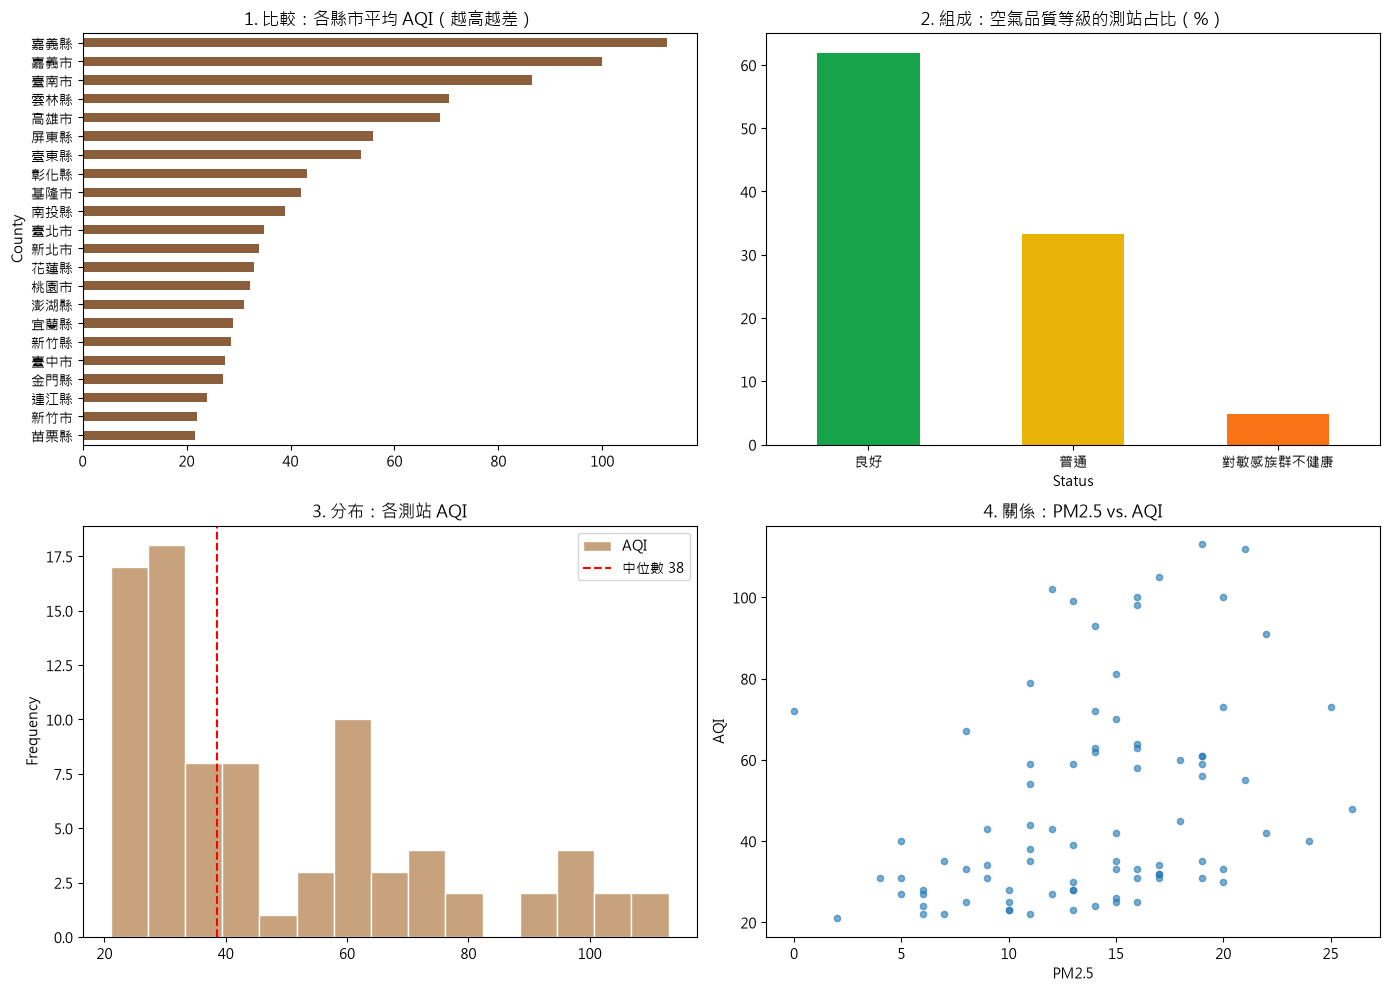

✅ 已存成 給AI的圖表/空氣品質四張圖.png


In [6]:
import os
import matplotlib.pyplot as plt
os.makedirs('給AI的圖表', exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# ① 比較：哪個縣市的平均 AQI 最高？→ 排序長條圖
county = aqi.groupby('County')['AQI'].mean().sort_values()
county.plot.barh(ax=axes[0, 0], color='#8B5E3C')
axes[0, 0].set_title('1. 比較：各縣市平均 AQI（越高越差）')

# ② 組成：各空氣品質等級的測站占比 → 依「好 → 壞」順序的長條圖
order = ['良好', '普通', '對敏感族群不健康', '對所有族群不健康', '非常不健康', '危害']
status = aqi['Status'].value_counts().reindex(order).dropna()
(status / status.sum() * 100).plot.bar(ax=axes[0, 1], color=['#16A34A', '#EAB308', '#F97316'][:len(status)], rot=0)
axes[0, 1].set_title('2. 組成：空氣品質等級的測站占比（%）')

# ③ 分布：AQI 集中在哪裡？→ 直方圖 + 中位數線
aqi['AQI'].plot.hist(ax=axes[1, 0], bins=15, color='#C8A27C', edgecolor='white')
axes[1, 0].axvline(aqi['AQI'].median(), color='red', linestyle='--', label=f"中位數 {aqi['AQI'].median():.0f}")
axes[1, 0].legend()
axes[1, 0].set_title('3. 分布：各測站 AQI')

# ④ 關係：PM2.5 越高，AQI 越高嗎？→ 散佈圖
aqi.plot.scatter(x='PM2.5', y='AQI', ax=axes[1, 1], alpha=0.6)
axes[1, 1].set_title('4. 關係：PM2.5 vs. AQI')

plt.tight_layout()
plt.savefig('給AI的圖表/空氣品質四張圖.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ 已存成 給AI的圖表/空氣品質四張圖.png')

## 第 4 步：把圖交給 AI——解讀、診斷、改良

**怎麼把圖給 AI？**
- 在 Colab 或 Jupyter 中，**對圖表按右鍵 →「複製圖片」**，直接貼到 AI 的對話框；或
- 從左側檔案區下載 `給AI的圖表/空氣品質四張圖.png`，再上傳給 AI。

**三種問法（建議三種都試試看）**：

> 🔎 **解讀**：「這是全台空氣品質測站某一小時的四張圖（附圖）。請用白話告訴我 3 個最重要的發現，每個發現都要指出是從哪張圖看出來的。」
>
> 🩺 **診斷**：「請以專業資料視覺化的標準檢查這四張圖：有沒有誤導、看不清楚或可以改進的地方？請具體說明要怎麼改。」
>
> 🛠️ **改良**：「請針對你認為最需要改進的那張圖，提供改良後的 matplotlib 程式碼（使用繁體中文標題）。」

## 第 5 步：驗證 AI 說的話——AI 會看錯圖！

AI 從圖片「目測」數字，常常會不精準，甚至把長條看錯。**AI 說出的每個數字，都要用 pandas 核對一次。**

In [7]:
print('▶ 平均 AQI 最高的 3 個縣市：\n', county.sort_values(ascending=False).head(3).round(1))
print('\n▶ 各等級測站數：\n', aqi['Status'].value_counts())
print('\n▶ AQI 中位數：', aqi['AQI'].median(), '｜最高：', aqi['AQI'].max(), aqi.loc[aqi['AQI'].idxmax(), 'SiteName'])
print('\n▶ PM2.5 與 AQI 的相關係數：', round(aqi['PM2.5'].corr(aqi['AQI']), 3))

▶ 平均 AQI 最高的 3 個縣市：
 County
嘉義縣    112.5
嘉義市    100.0
臺南市     86.5
Name: AQI, dtype: float64

▶ 各等級測站數：
 Status
良好          52
普通          28
對敏感族群不健康     4
Name: count, dtype: int64

▶ AQI 中位數： 38.5 ｜最高： 113 新港

▶ PM2.5 與 AQI 的相關係數： 0.362


> 🔍 **一個常見的 AI 誤判**：PM2.5 和 AQI 的相關係數只有 0.36 左右，並沒有想像中高。原因是 AQI 取的是「各項污染物分項指標中最差的一項」——有些測站的主要污染物是懸浮微粒（PM10）或二氧化氮（看 `Pollutant` 欄）。如果 AI 斷言「PM2.5 越高，AQI 一定越高」，你就該打個問號。
>
> 💡 **驗收 AI 建議的 3 個問題**：
> 1. AI 說的數字和上面算出來的一樣嗎？
> 2. AI 有沒有提醒你：這份資料**只是某一個小時**的觀測，不能說「某縣市的空氣一直都比較差」？
> 3. AI 建議的改法，套用後真的比較好讀嗎？——**最後做決定的是你，不是 AI。**

---

## ✍️ 延伸挑戰

1. 把 `CO` 轉成數字（`pd.to_numeric(..., errors='coerce')`），再用健檢工具檢查一次，型態判斷有變嗎？
2. 用 `Longitude`、`Latitude` 畫散佈圖，點的顏色用 AQI（`c='AQI'`、`cmap='RdYlGn_r'`），看起來像什麼？把這張圖交給 AI，請它解讀地理上的分布。
3. 回到課堂範例的「茶語時光」資料，用同樣的流程挑一個你自己的問題，畫圖、交給 AI、再驗證。

## 🔑 延伸挑戰參考程式

   判斷型態  缺值%
欄位          
CO   數值  4.8


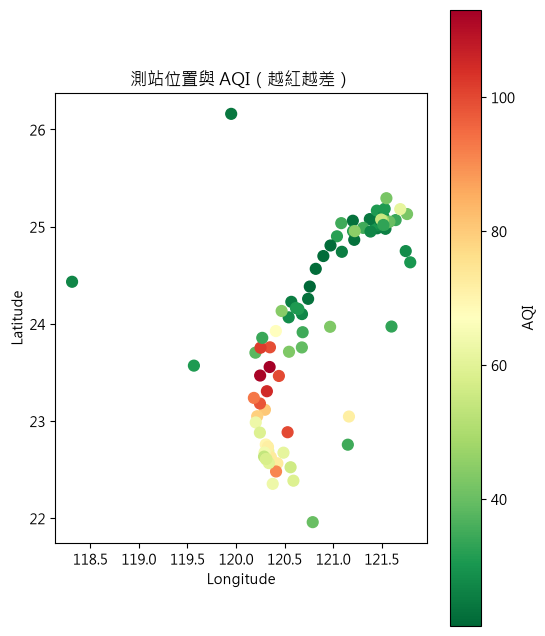

In [8]:
# 延伸 1
aqi['CO'] = pd.to_numeric(aqi['CO'], errors='coerce')
print(認識資料(aqi).loc[['CO'], ['判斷型態', '缺值%']])

# 延伸 2
ax = aqi.plot.scatter(x='Longitude', y='Latitude', c='AQI', cmap='RdYlGn_r', s=60, figsize=(6, 8),
                      title='測站位置與 AQI（越紅越差）')
ax.set_aspect('equal')
plt.savefig('給AI的圖表/測站地圖.png', dpi=150, bbox_inches='tight')
plt.show()